# Demo 2: Effects, model checking and mgcViz (Python / pymgcv)

This notebook is the Python version of [`R_demos/2_effects_and_mgcViz.R`](../R_demos/2_effects_and_mgcViz.R).
It has two parts:

1. **GEFCom14 load data**: plotting the effects of a GAM and checking whether the
   temperature effect is modelled correctly.
2. **Larynx cancer in Germany**: Poisson GAMs with an offset, checking for spatial patterns
   in the residuals, and adding spatial effects.

In R, most plots in this demo come from [mgcViz](https://mfasiolo.github.io/mgcViz/), a
package for visualising and checking GAMs built on `ggplot2`. There is no Python version
of mgcViz, so this notebook uses three approaches:

- **pymgcv** where it has an equivalent (effect plots, QQ plots, 2D residual checks).
- **numpy + matplotlib** to rebuild the mgcViz checks that pymgcv lacks.
- **rpy2** to call mgcViz (and mgcv) directly in R and show the R plot inside the
  notebook, for comparison and where pymgcv is missing a feature.

## R → Python summary

| R (mgcv / mgcViz) | Python in this notebook | Notes |
|---|---|---|
| `plot(fit, all.terms = TRUE)` | `gplt.plot(fit)` | pymgcv ✅ |
| `getViz(fit, nsim = 100)` / `gamV()` | not needed | Plots work directly on the fitted `GAM`; simulations are done by the helper below |
| `plot(fit, select = 1) + l_fitLine()` | `gplt.continuous_1d(...)` | pymgcv ✅ |
| `+ l_fitDens()` | `fit_density_plot()` helper | ⚠️ not in pymgcv, built with numpy/matplotlib |
| `check1D(fit, "wM") + l_gridCheck1D()` | `grid_check_1d()` helper | ⚠️ not in pymgcv, built with numpy/matplotlib |
| `check(fit)` | `model_check()` helper + `fit.check_k()` | ⚠️ pymgcv has the pieces (`qq`, `residuals_vs_linear_predictor`, `check_k`), not the 4-panel figure |
| `qq(fit)` | `gplt.qq(fit)` | pymgcv ✅ |
| `check2D(fit, x1, x2) + l_gridCheck2D()` | `gplt.hexbin_residuals(...)` | pymgcv ✅, but without simulation-based standardisation |
| `s(region, bs = "mrf", xt = list(polys = ...))` | rpy2 + mgcv | ❌ pymgcv has `MarkovRandomField`, but passing the polygons is not implemented yet |
| `plot(fit, select = 1)` for an MRF | `plot_map()` helper | Choropleth map with matplotlib |
| `s(lo, la, k = 200)` + `plot(...)` | `S("lo", "la", k=200)` + `gplt.plot(...)` | pymgcv ✅ |
| `plotRGL(sm(fit, 1))` | plotly 3D surface | Interactive, like rgl: rotate with the mouse |

In [1]:
%matplotlib inline
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import rpy2.robjects as ro
from IPython.display import Image, display
from matplotlib.collections import PolyCollection
from matplotlib.colors import TwoSlopeNorm
from rpy2.robjects.packages import importr

import pymgcv.plot as gplt
from pymgcv.basis_functions import CubicSpline
from pymgcv.families import Poisson
from pymgcv.gam import GAM
from pymgcv.terms import L, Offset, S
from pymgcv.utils import load_rdata_dataframe_from_url
from plot_helpers import plot_surface_static  # helper file next to the notebooks

# R packages, used through rpy2
grdevices = importr("grDevices")
importr("mgcViz")  # also loads mgcv

DATA_URL = "https://raw.githubusercontent.com/mfasiolo/testGam/master/data/"

## Helper functions

pymgcv covers fitting and the basic plots. The helpers below fill the gaps listed in the
table above. You don't need to understand them in detail to follow the demo.

- `show_r_plot(r_code)`: runs R plotting code (base R, ggplot2 or mgcViz) and shows the
  result in the notebook. Use it to compare with the R demo.
- `simulate_residuals(fit)`: simulates new responses from the fitted model and returns
  their residuals. This is what `getViz(fit, nsim = 100)` does in R.
- `grid_check_1d(fit, var)`: Python version of `check1D(fit, var) + l_gridCheck1D()`.
- `fit_density_plot(fit, term)`: Python version of `l_fitDens() + l_fitLine()`.
- `model_check(fit)`: Python version of the 4 plots from `check(fit)` / `gam.check(fit)`.

In [2]:
def show_r_plot(r_code, width=7, height=5, res=100):
    """Run R plotting code and display the resulting figure in the notebook.

    ggplot2/mgcViz objects must be printed, e.g. show_r_plot("print(qq(v))").
    """
    with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as f:
        path = f.name
    grdevices.png(path, width=width, height=height, units="in", res=res)
    try:
        ro.r(r_code)
    finally:
        grdevices.dev_off()
    display(Image(path))


def to_r(name, model):
    """Make the mgcv object behind a pymgcv model available in R under `name`."""
    ro.globalenv[name] = model.fit_state.rgam


def simulate_residuals(model, n_sim=100, seed=1):
    """Simulate n_sim responses from the fitted model and return their deviance residuals.

    Returns an array of shape (n_sim, n_obs). Equivalent to getViz(model, nsim = n_sim).
    """
    ro.r(f"set.seed({seed})")
    rgam = model.fit_state.rgam
    mu = np.array(ro.r["fitted"](rgam))
    wt = np.array(ro.r["weights"](rgam, type="prior"))
    scale = np.array(rgam.rx2("sig2"), dtype=float)  # residual variance (1 for Poisson)
    sims = []
    for _ in range(n_sim):
        y_sim = model.family.sample(mu=mu, wt=wt, scale=scale)
        sims.append(model.residuals_from_y_and_fit(y=y_sim, fit=mu, weights=wt))
    return np.array(sims)


def grid_check_1d(model, var, values=None, n=20, n_sim=100, level=0.8, ax=None, seed=1):
    """Python version of mgcViz's check1D(model, var) + l_gridCheck1D().

    The range of `var` is split into n - 1 bins. In each bin we compute
    sum(residuals) / sqrt(count), i.e. the mean residual times sqrt(count), for the
    observed residuals (black dots) and for residuals simulated from the model (grey).
    If the model is correct, the black dots should lie inside the red band, which
    contains `level` of the simulated values.
    """
    x = np.asarray(model.fit_state.data[var] if values is None else values, dtype=float)
    res = model.residuals()
    sims = simulate_residuals(model, n_sim=n_sim, seed=seed)

    grid = np.linspace(x.min(), x.max(), n)
    bins = np.clip(np.searchsorted(grid, x, side="right") - 1, 0, n - 2)
    used = np.unique(bins)

    def stat(r):
        return np.array([r[bins == b].sum() / np.sqrt((bins == b).sum()) for b in used])

    x_mid = np.array([x[bins == b].mean() for b in used])
    obs = stat(res)
    sim_stats = np.array([stat(s) for s in sims])
    lo, hi = np.quantile(sim_stats, [(1 - level) / 2, (1 + level) / 2], axis=0)

    ax = plt.gca() if ax is None else ax
    ax.scatter(np.tile(x_mid, n_sim), sim_stats.ravel(), s=1, color="grey", alpha=0.5)
    ax.plot(x_mid, lo, "--", color="red")
    ax.plot(x_mid, hi, "--", color="red")
    ax.scatter(x_mid, obs, color="black", zorder=3)
    ax.set(xlabel=var, ylabel="binned residuals")
    return ax


def fit_density_plot(model, term, n_bins=50, ax=None):
    """Python version of plot(model, select = i) + l_fitDens() + l_fitLine().

    The background shows the conditional density of the partial residuals given x
    (each column is normalised), with the fitted effect on top.
    """
    x = np.asarray(model.fit_state.data[term.varnames[0]], dtype=float)
    pres = model.partial_residuals(term)
    ax = plt.gca() if ax is None else ax
    hist, xe, ye = np.histogram2d(x, pres, bins=n_bins)
    hist = hist / np.maximum(hist.sum(axis=1, keepdims=True), 1)
    ax.pcolormesh(xe, ye, hist.T, cmap="Greys", shading="flat")
    gplt.continuous_1d(term=term, gam=model, ax=ax,
                       fill_between_kwargs={"disable": True},
                       plot_kwargs={"color": "C3"})
    return ax


def model_check(model):
    """Python version of the four plots from check(model) / gam.check(model)."""
    fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
    gplt.qq(model, ax=axes[0, 0])
    axes[0, 0].set_title("QQ plot of residuals")
    gplt.residuals_vs_linear_predictor(model, ax=axes[0, 1])
    axes[0, 1].set_title("Residuals vs linear predictor")
    axes[1, 0].hist(model.residuals(), bins=50, color="grey")
    axes[1, 0].set(title="Histogram of residuals", xlabel="residuals")
    y = np.array(ro.r["fitted"](model.fit_state.rgam))
    response = list(model.predictors)[0]
    axes[1, 1].scatter(y, model.fit_state.data[response], s=3, alpha=0.5)
    axes[1, 1].set(title="Response vs fitted values", xlabel="fitted values",
                   ylabel=response)
    return fig

# Part 1: GEFCom14 load data

Same data as in Demo 1: daily electricity net demand, trained on the years before 2011 and
tested on 2011. As before, `Dow` is converted to a `category` so that it is treated as a
factor.

In [3]:
data = load_rdata_dataframe_from_url(DATA_URL + "gefcom_small.rda")
data["Dow"] = data["Dow"].astype("category")

train = data[data["Year"] < 2011].reset_index(drop=True)
test = data[data["Year"] == 2011].reset_index(drop=True)
data.head()

,Year,NetDemand,wM,Posan,Trend,Dow,wM_s95,NetDemand.24
1,2005,2.889407,16.388889,0.00137,0.000000,6,8.236849,2.889407
2,2005,2.543342,17.361111,0.00411,0.000396,0,9.933947,2.889407
3,2005,2.446159,18.888889,0.00685,0.000792,1,10.794862,2.543342
4,2005,2.190166,21.250000,0.00959,0.001189,2,14.462260,2.446159
5,2005,2.100094,20.833333,0.01233,0.001585,3,16.194613,2.190166


## Plotting all the effects

We start from the first model of Demo 1, where temperature has a **linear** effect.
As in Demo 1, we use `method="GCV.Cp"` to match R's default.

R:

```r
fit1 <- gam(NetDemand ~ NetDemand.24 + Dow + Trend + wM + wM_s95 + s(Posan, bs = "cc"), data = train)
plot(fit1, all.terms = TRUE, pages = 1)
```

`gplt.plot` plots every term by default, including the linear terms and the factor `Dow`
(R needs `all.terms = TRUE` for that).

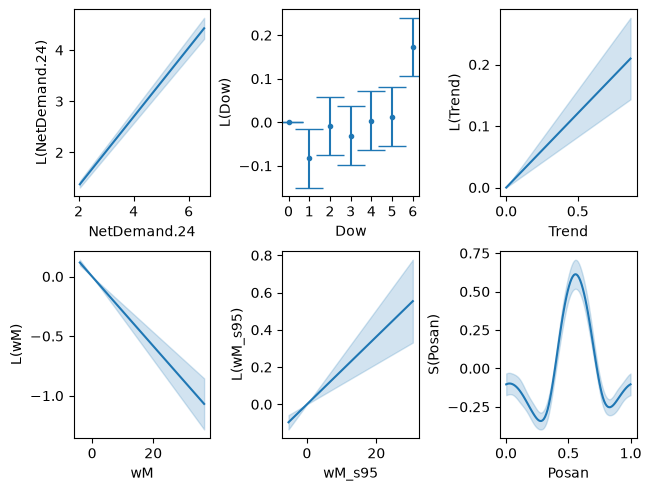

In [4]:
METHOD = "GCV.Cp"

fit1 = GAM({
    "NetDemand": [
        L("NetDemand.24"),
        L("Dow"),
        L("Trend"),
        L("wM"),
        L("wM_s95"),
        S("Posan", bs=CubicSpline(cyclic=True)),
    ]
})
fit1.fit(train, method=METHOD)

fig, _ = gplt.plot(fit1, ncols=3)

In R, `class(fit1)` and `args(plot.gam)` show the object type and the plotting options.
In Python, use `type(...)` and `help(...)`, or `gplt.plot?` in Jupyter.

In [5]:
print(type(fit1))
help(gplt.plot)

<class 'pymgcv.gam.GAM'>
Help on function plot in module pymgcv.plot:

plot(
    gam: pymgcv.gam.AbstractGAM,
    *,
    ncols: int = 2,
    scatter: bool = False,
    data: pandas.core.frame.DataFrame | collections.abc.Mapping[str, numpy.ndarray | pandas.core.series.Series] | None = None,
    to_plot: type | types.UnionType | dict[str, list[pymgcv.terms.AbstractTerm]] = <class 'pymgcv.terms.AbstractTerm'>,
    kwargs_mapper: dict[collections.abc.Callable, dict[str, typing.Any]] | None = None
) -> tuple[matplotlib.figure.Figure, matplotlib.axes._axes.Axes | numpy.ndarray]
    Plot a gam model.

    Except for some specialised cases, this plots the partial effects of the terms.

    Args:
        gam: The fitted gam object to plot.
        ncols: The number of columns before wrapping axes.
        scatter: Whether to plot the residuals (where possible), and the overlayed
            datapoints on 2D plots. For more fine control, see `kwargs_mapper`. Defaults
            to False.
      

## From `plot.gam` to mgcViz layers

In R, `getViz()` converts the `gam` object into a `gamViz` object. Its plots are ggplot2
objects that you build up with **layers**: `l_fitLine()` draws the fitted effect,
`l_fitDens()` the density of the partial residuals, and so on.

pymgcv doesn't need a conversion step: its plotting functions take the fitted model
directly and draw with matplotlib. The layers become keyword arguments, or extra
matplotlib calls on the same axes.

`plot(fit1, select = 1) + l_fitLine()` plots the first smooth, `s(Posan)`:

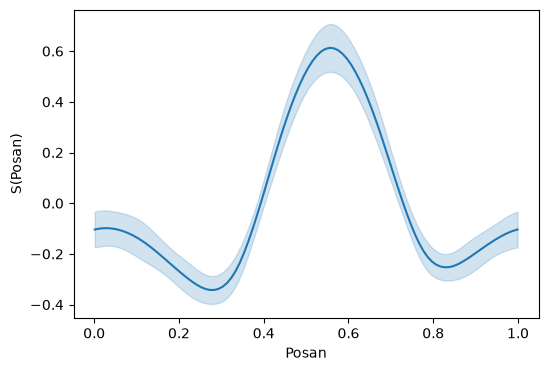

In [6]:
# The term to plot: the same S(...) as in the model definition
posan_term = S("Posan", bs=CubicSpline(cyclic=True))

fig, ax = plt.subplots(figsize=(6, 4))
gplt.continuous_1d(term=posan_term, gam=fit1, ax=ax);

`plot(fit1, select = 1) + l_fitDens() + l_fitLine()` adds the conditional density of the
**partial residuals** in the background. Partial residuals are the residuals plus the
estimated effect of the term, so if the effect is right they should be centred on the
fitted line. pymgcv has no density layer, so we use the `fit_density_plot` helper:

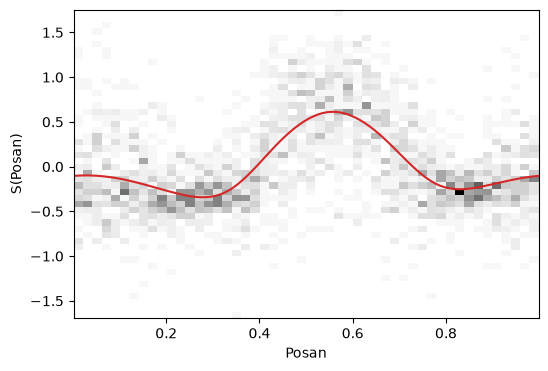

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
fit_density_plot(fit1, posan_term, ax=ax);

For comparison, the same two mgcViz plots made in R through rpy2. `to_r` passes the mgcv
model fitted by pymgcv to R, so mgcViz works on exactly the same fit.

In addition: Warning message:
Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the mgcViz package.
  Please report the issue at <https://github.com/mfasiolo/mgcViz/issues>.
This warning is displayed once per session.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 


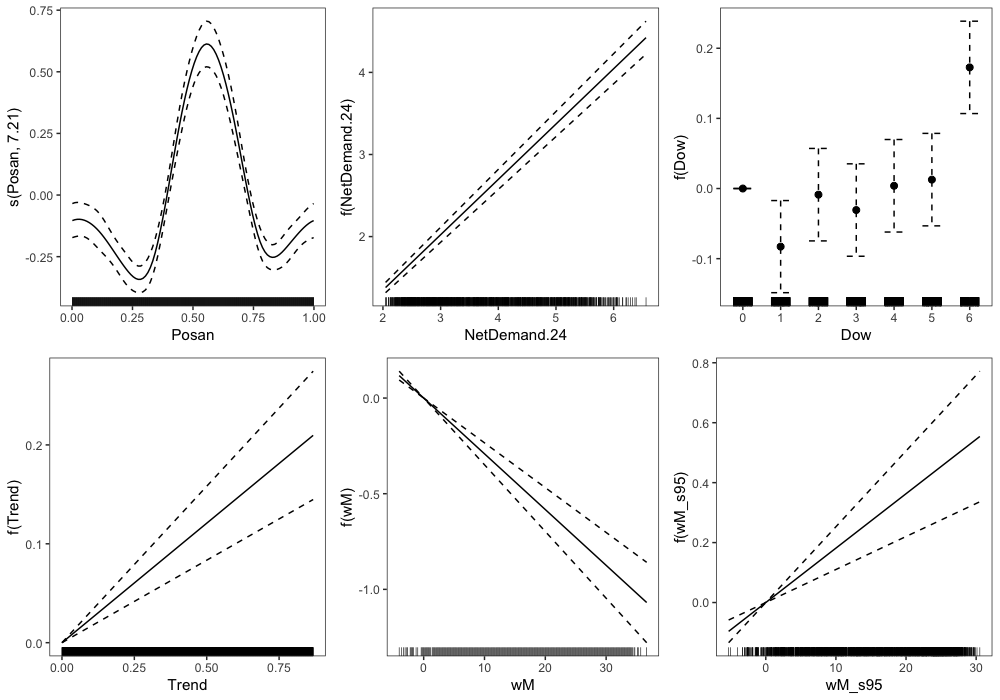

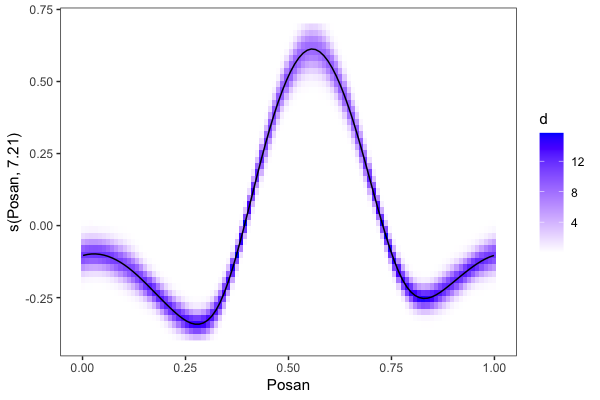

In [8]:
to_r("fit1", fit1)
ro.r("set.seed(1); fit1_viz <- getViz(fit1, nsim = 100)")

show_r_plot("print(plot(fit1_viz, allTerms = TRUE), pages = 1)", width=10, height=7)
show_r_plot("print(plot(fit1_viz, select = 1) + l_fitDens() + l_fitLine())", width=6, height=4)

## Is the temperature effect right?

Plotting the residuals of fit1 against temperature, there is a clear pattern: the model
over-predicts at medium temperatures and under-predicts when it's cold or hot.

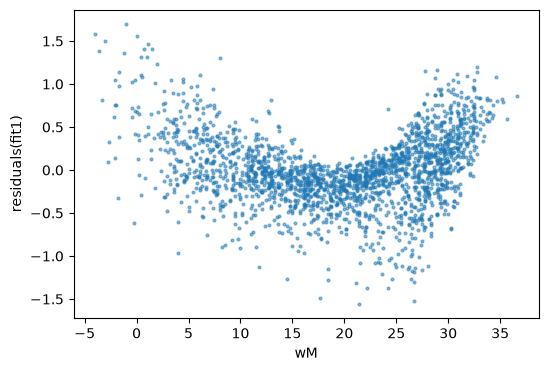

In [9]:
res1 = fit1.residuals()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(train["wM"], res1, s=4, alpha=0.5)
ax.set(xlabel="wM", ylabel="residuals(fit1)");

### How the binned residual check works

This cell only illustrates the idea behind `l_gridCheck1D()`, as in the R demo:

1. split the range of `wM` into bins (the ticks at the bottom),
2. colour the residuals by bin,
3. compute the mean of `wM` and of the residuals in each bin (large black dots).

If the model were correct, the bin means would scatter around zero with no pattern.

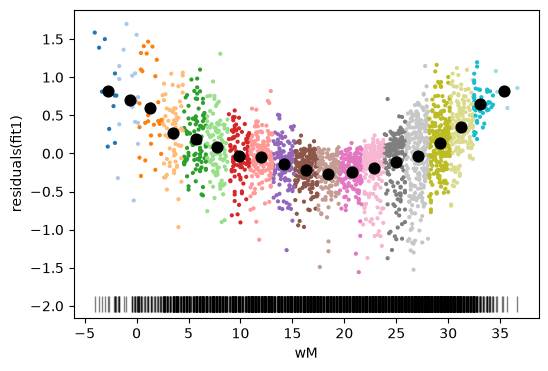

In [10]:
x = train["wM"].to_numpy()
y = res1
n = 20
grid = np.linspace(x.min(), x.max(), n)
in_x = np.clip(np.searchsorted(grid, x, side="right") - 1, 0, n - 2)

grX = np.array([x[in_x == b].mean() for b in np.unique(in_x)])
grY = np.array([y[in_x == b].mean() for b in np.unique(in_x)])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, c=in_x, cmap="tab20", s=4)
ax.plot(x, np.full_like(x, y.min()-y.std()), "|", alpha=0.5, color="black", ms=12, mew=1)  # rug(grid)
ax.scatter(grX, grY, color="black", s=60)
ax.set(xlabel="wM", ylabel="residuals(fit1)");

### `check1D(fit1, "wM") + l_gridCheck1D()`

The full check also tells us how much the binned residuals would vary **if the model
were correct**. We simulate 100 new responses from fit1 (this is what `getViz(nsim = 100)`
does), compute their residuals, and bin them in the same way (grey dots). The red dashed
lines contain 80% of the simulated values. Many black dots fall far outside the band, so
the linear temperature effect is clearly wrong.

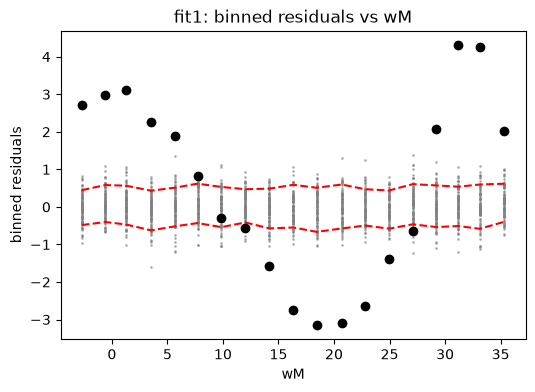

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
grid_check_1d(fit1, "wM", ax=ax)
ax.set_title("fit1: binned residuals vs wM");

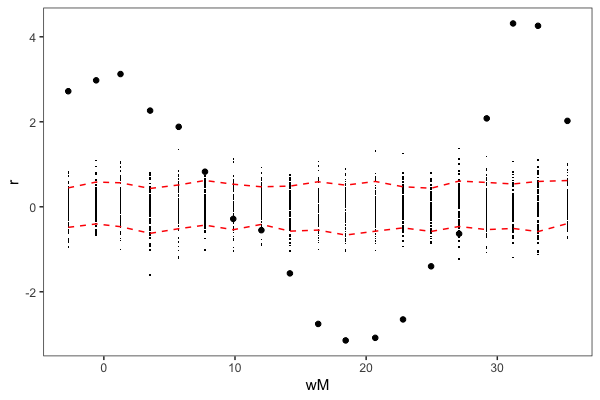

In [12]:
# The same check with mgcViz, through rpy2
show_r_plot('print(check1D(fit1_viz, "wM") + l_gridCheck1D())', width=6, height=4)

## fit2: smooth temperature effects

We replace the linear temperature terms with smooths and repeat the check. The black dots
now lie inside the band, so the smooth captures the effect of temperature.

In R, `gamV()` is a shortcut for `gam()` followed by `getViz()`. In Python we just fit the
model, because the helpers work on any fitted `GAM`.

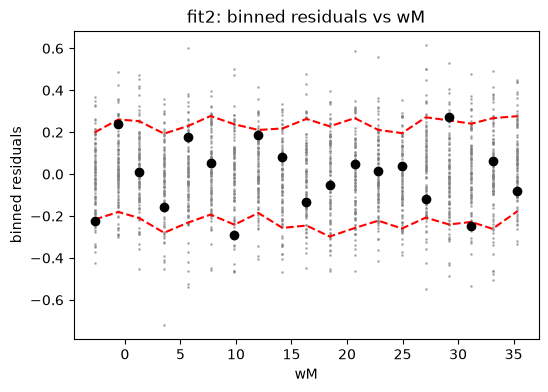

In [13]:
fit2 = GAM({
    "NetDemand": [
        L("NetDemand.24"),
        L("Dow"),
        L("Trend"),
        S("wM"),     # <- previous version was linear L("wM"), but we now use a smooth term S("wM")
        S("wM_s95"), # <- previous version was linear L("wM_s95"), but we now use a smooth term S("wM_s95")
        S("Posan", bs=CubicSpline(cyclic=True)),
    ]
})
fit2.fit(train, method=METHOD)

fig, ax = plt.subplots(figsize=(6, 4))
grid_check_1d(fit2, "wM", ax=ax)
ax.set_title("fit2: binned residuals vs wM");

## `check(fit2)` and `qq(fit2)`

`check()` (mgcViz) and `gam.check()` (mgcv) show four standard residual plots and the
basis-dimension check. pymgcv has the individual pieces; `model_check` puts them in one
figure, and `check_k()` gives the basis-dimension table.

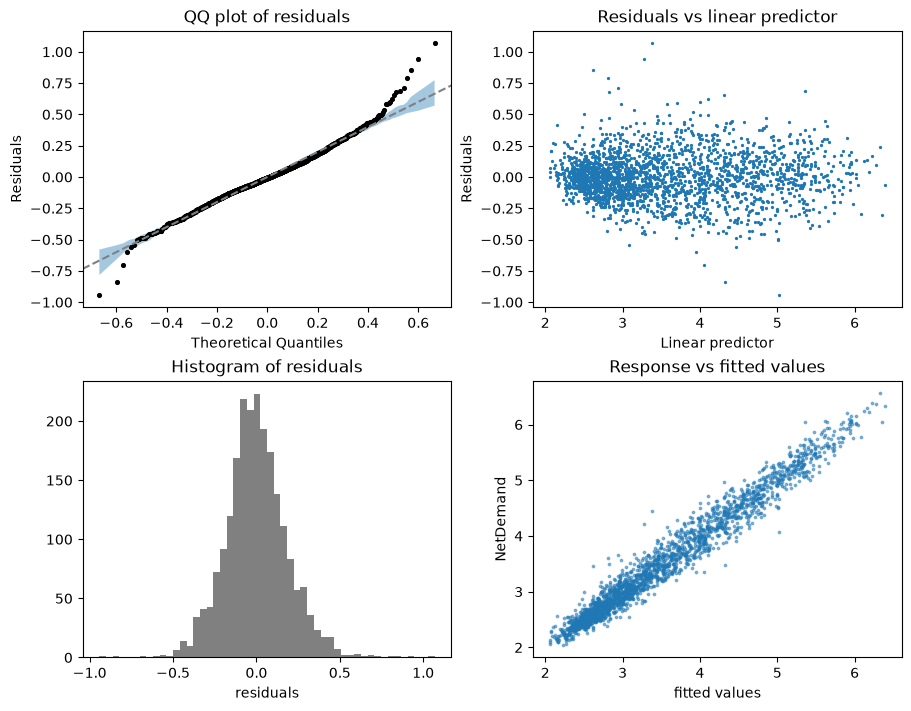

In [14]:
model_check(fit2);

In [15]:
fit2.check_k()

,term,max_edf,edf,k_index,p_value
0,s(wM),9.0,8.524790,0.938984,0.000
1,s(wM_s95),9.0,7.835844,1.029025,0.890
2,s(Posan),8.0,7.639076,1.020706,0.805


`qq(fit2)`: the QQ plot of the residuals, with a reference band from simulated residuals.

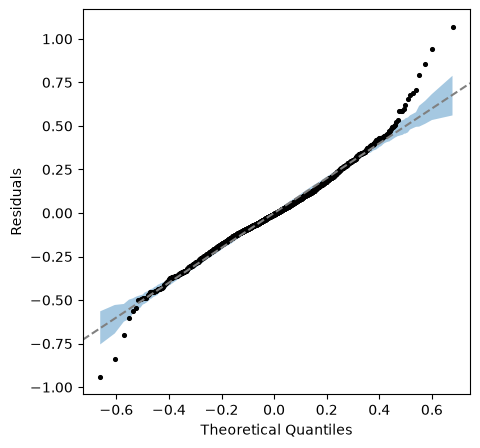

In [16]:
fig, ax = plt.subplots(figsize=(5, 5))
gplt.qq(fit2, ax=ax);

# Part 2: Larynx cancer in Germany

## The data

`Larynx` has one row per district in Germany (544 districts):

- **`Y`**: observed number of deaths from larynx cancer. This is the **response**: a
  count, so we use a **Poisson** model.
- **`E`**: expected number of deaths, based on the district's population. Bigger
  districts have more deaths simply because more people live there.
- **`x`**: a covariate measuring the level of smoking consumption in the district.
- **`region`**: district identifier, used later for the spatial effect.

`german.polys` holds the polygon (boundary) of each district. We load it into R with rpy2
and convert each polygon to a numpy array of (x, y) map coordinates. Some polygons
contain rows of `NaN` that separate several pieces of the same district.

In [17]:
larynx = load_rdata_dataframe_from_url(DATA_URL + "Larynx.rda")

ro.r(f'load(url("{DATA_URL}german.polys.rda"))')
r_polys = ro.globalenv["german.polys"]
polys = {name: np.asarray(p) for name, p in zip(r_polys.names, r_polys)}

larynx.head()

,region,E,Y,x
1,0,7.965008,8,56
2,1,22.836219,22,65
3,2,22.094716,19,50
4,3,7.919352,3,63
5,4,13.139889,14,65


To look for spatial patterns we need a location for each district. As in R, we use the
centre of each polygon (`colMeans(..., na.rm = TRUE)`) and call its coordinates `lo`
(east–west) and `la` (north–south). They are projected map coordinates, not degrees.

In [18]:
centres = np.array([np.nanmean(polys[r], axis=0) for r in larynx["region"]])
larynx["lo"] = centres[:, 0]
larynx["la"] = centres[:, 1]
larynx["logE"] = np.log(larynx["E"])  # used for the offset below

The `plot_map` helper draws a value per district as a map. Here it shows the observed
ratio `Y / E` (above 1 means more deaths than expected).

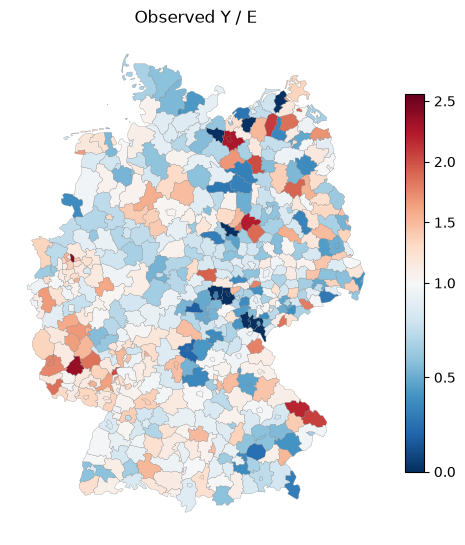

In [19]:
def plot_map(values, regions, ax=None, cmap="RdBu_r", center=None, title=None):
    """Choropleth map: colour each district polygon by its value."""
    ax = plt.gca() if ax is None else ax
    shapes, colours = [], []
    for region, value in zip(regions, values):
        poly = polys[region]
        # Split polygons with several pieces at the NaN separator rows
        pieces = np.split(poly, np.where(np.isnan(poly[:, 0]))[0])
        for piece in pieces:
            piece = piece[~np.isnan(piece[:, 0])]
            if len(piece) > 2:
                shapes.append(piece)
                colours.append(value)
    colours = np.asarray(colours)
    # With `center`, values above it are red and values below it blue
    norm = None if center is None else TwoSlopeNorm(vcenter=center)
    coll = PolyCollection(shapes, array=colours, cmap=cmap, norm=norm,
                          edgecolor="grey", linewidth=0.2)
    ax.add_collection(coll)
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title)
    plt.colorbar(coll, ax=ax, shrink=0.7)
    return ax


fig, ax = plt.subplots(figsize=(6, 7))
plot_map(larynx["Y"] / larynx["E"], larynx["region"], ax=ax, center=1, title="Observed Y / E");

## fit1: effect of smoking only

R:

```r
fit1 <- gamV(Y ~ s(x, k = 20),
             family = poisson,
             data = Larynx,
             aViz = list(nsim = 100))
check2D(fit1, x1 = Larynx$lo, x2 = Larynx$la) + l_gridCheck2D()
```

`check2D` + `l_gridCheck2D` bins the residuals in space (`lo` × `la`). pymgcv's
`hexbin_residuals` does the same with hexagonal bins: each hexagon shows
`sum(residuals) / sqrt(count)`. Red areas have more deaths than the model predicts, blue
areas fewer. Large, smooth patches of colour mean there is spatial structure that the
model is missing.

Note that mgcViz additionally standardises each hexagon using the simulated residuals;
`hexbin_residuals` doesn't, so the colour scale differs but the patterns are the same.

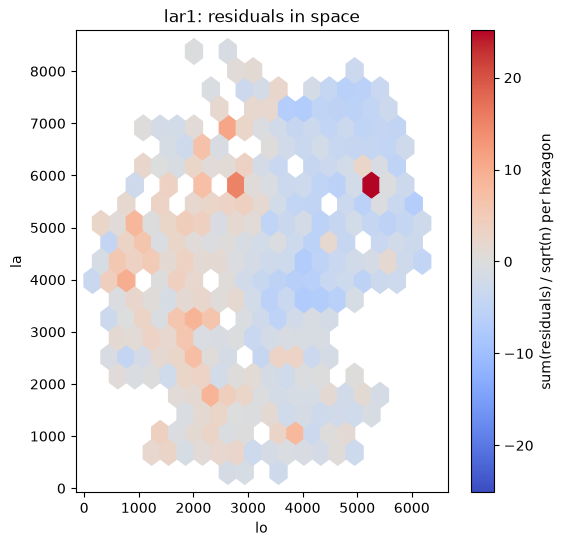

In [20]:
lar1 = GAM({"Y": [S("x", k=20)]},
           family=Poisson())
lar1.fit(larynx)

fig, ax = plt.subplots(figsize=(6, 6))
gplt.hexbin_residuals(lar1.residuals(), "lo", "la", larynx, gridsize=20, ax=ax)
fig.colorbar(ax.collections[-1], ax=ax, label="sum(residuals) / sqrt(n) per hexagon")
ax.set_title("lar1: residuals in space");

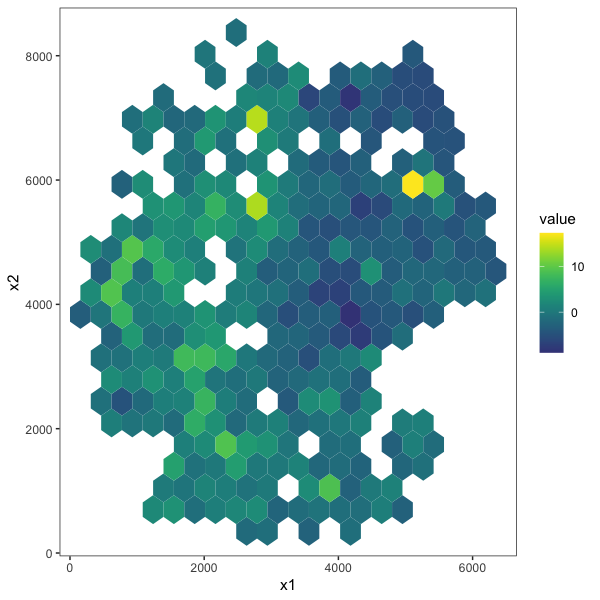

In [21]:
# The same check with mgcViz, through rpy2
to_r("lar1", lar1)
ro.globalenv["lo"] = ro.FloatVector(larynx["lo"])
ro.globalenv["la"] = ro.FloatVector(larynx["la"])
ro.r("set.seed(1); lar1_viz <- getViz(lar1, nsim = 100)")
show_r_plot("print(check2D(lar1_viz, x1 = lo, x2 = la) + l_gridCheck2D())", width=6, height=6)

## fit2: adding the offset `log(E)`

Most of the pattern above is just population: districts with more people have more
deaths. We include the expected number of deaths as an **offset**, a term with a fixed
coefficient of 1:

$$
\mathbb{E}(Y) = \exp\big(s(x) + \log E\big) = E \cdot \exp\big(s(x)\big)
$$

In R:

```r
fit2 <- gamV(Y ~ s(x, k = 20) + offset( log(E)),
             family = poisson,
             data = Larynx,
             aViz = list(nsim = 100))
```

so $\exp(s(x))$ is the ratio between observed and expected deaths. In pymgcv,
`Offset("logE")` uses a column of the data as the offset, so we created `logE` earlier.

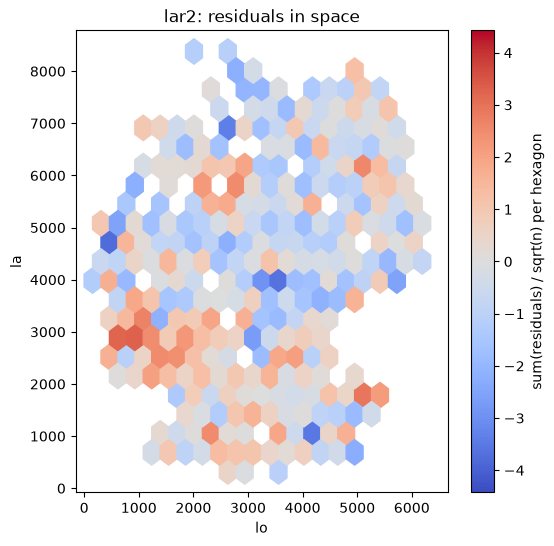

In [22]:
lar2 = GAM({"Y": [S("x", k=20),
                  Offset("logE")]},
           family=Poisson())
lar2.fit(larynx)

fig, ax = plt.subplots(figsize=(6, 6))
gplt.hexbin_residuals(lar2.residuals(), "lo", "la", larynx, gridsize=20, ax=ax)
fig.colorbar(ax.collections[-1], ax=ax, label="sum(residuals) / sqrt(n) per hexagon")
ax.set_title("lar2: residuals in space");

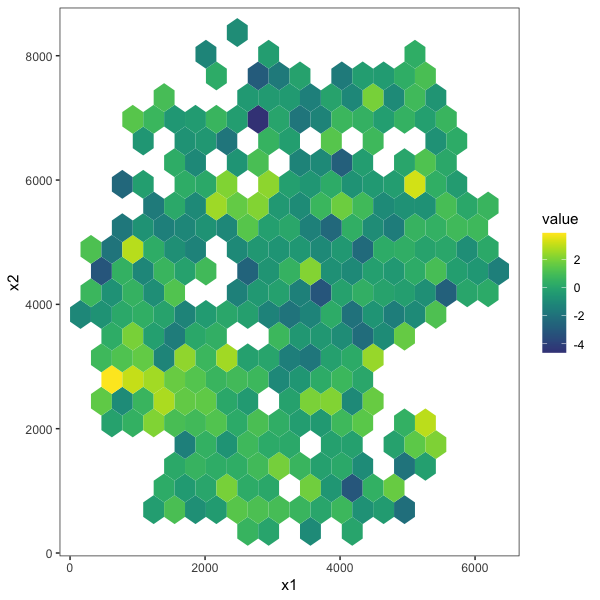

In [23]:
to_r("lar2", lar2)
ro.r("set.seed(1); lar2_viz <- getViz(lar2, nsim = 100)")
show_r_plot("print(check2D(lar2_viz, x1 = lo, x2 = la) + l_gridCheck2D())", width=6, height=6)

There is still a spatial pattern (e.g. high values in the south), so we add a spatial
effect.

## fit3: a Markov random field (MRF) smooth over districts

An MRF smooth gives each district its own effect, and the penalty makes **neighbouring**
districts have similar effects. mgcv works out the neighbours from the polygons.

R:

```r
fit3 <- gamV(Y ~ s(region, k = 200, bs = "mrf", xt = list(polys = german.polys)) +
                 s(x, k = 20) + offset(log(E)),
             family = poisson,
             data = Larynx,
             aViz = list(nsim = 100))
```

> ⚠️ **pymgcv limitation:** pymgcv has a `MarkovRandomField` basis, but it can't pass
> the polygons to mgcv yet (`xt = list(polys = ...)` is not implemented), so the model
> can't be fitted with pymgcv. Instead we fit it **directly with mgcv through rpy2**,
> then bring the results back to Python.

In [24]:
ro.r(f'load(url("{DATA_URL}Larynx.rda"))')  # loads `Larynx` (with `region` as a factor)
ro.r("Larynx$lo <- lo; Larynx$la <- la")

ro.r("""
lar3 <- gam(Y ~ s(region, k = 200, bs = "mrf", xt = list(polys = german.polys)) +
                s(x, k = 20) + offset(log(E)),
            family = poisson,
            data = Larynx,
            aViz = list(nsim = 100))
""")
print("\n".join(ro.r("capture.output(summary(lar3))")))


Family: poisson 
Link function: log 

Formula:
Y ~ s(region, k = 200, bs = "mrf", xt = list(polys = german.polys)) + 
    s(x, k = 20) + offset(log(E))

Parametric coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept) -0.03787    0.01432  -2.644  0.00819 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Approximate significance of smooth terms:
             edf Ref.df Chi.sq  p-value    
s(region) 59.970  92.87 180.32  < 2e-16 ***
s(x)       1.151   1.26  28.56 7.38e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

R-sq.(adj) =  0.951   Deviance explained = 41.2%
UBRE = 0.082637  Scale est. = 1         n = 544


The residual check now shows no clear spatial pattern. We compute the residuals in R and
use the same pymgcv `hexbin_residuals` plot as before.

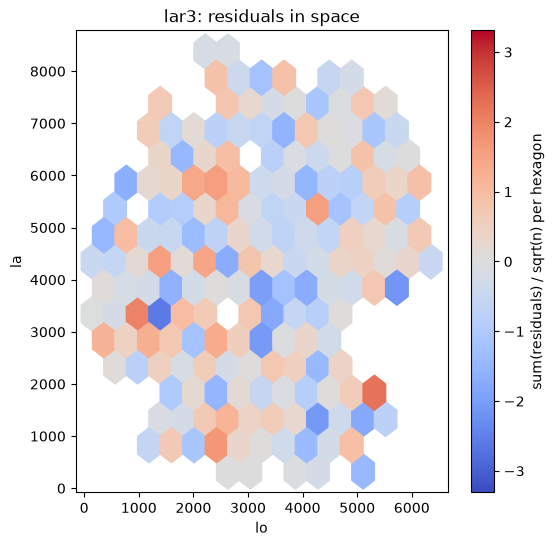

In [25]:
res3 = np.array(ro.r("residuals(lar3)"))

fig, ax = plt.subplots(figsize=(6, 6))
gplt.hexbin_residuals(res3, "lo", "la", larynx, gridsize=15, ax=ax)
fig.colorbar(ax.collections[-1], ax=ax, label="sum(residuals) / sqrt(n) per hexagon")
ax.set_title("lar3: residuals in space");

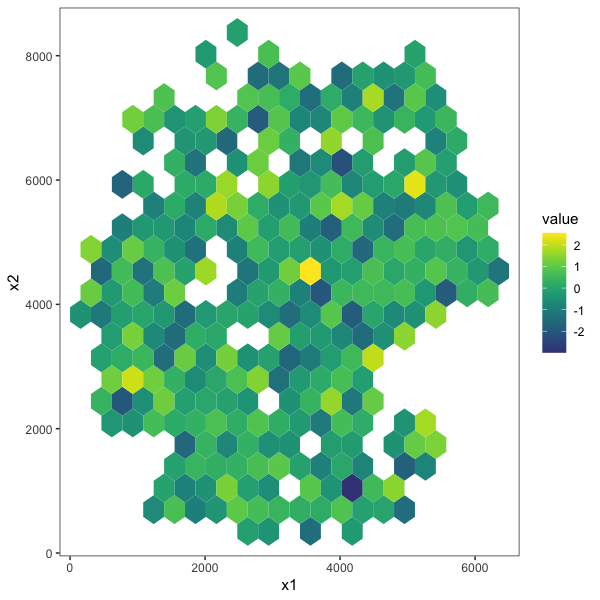

In [26]:
ro.r("set.seed(1); lar3_viz <- getViz(lar3, nsim = 100)")
show_r_plot("print(check2D(lar3_viz, x1 = lo, x2 = la) + l_gridCheck2D())", width=6, height=6)

`plot(fit3, select = 1)` shows the MRF effect as a map. We get the estimated effect of
each district from `predict(..., type = "terms")` and draw it with `plot_map`. Positive
values (red) mean more deaths than expected given smoking.

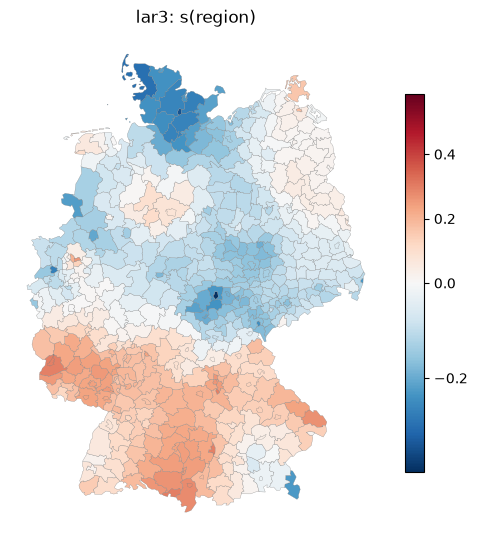

In [27]:
region_effect = np.array(ro.r('predict(lar3, type = "terms")[, "s(region)"]'))
region_names = list(ro.r("as.character(Larynx$region)"))

fig, ax = plt.subplots(figsize=(6, 7))
plot_map(region_effect, region_names, ax=ax, center=0, title="lar3: s(region)");

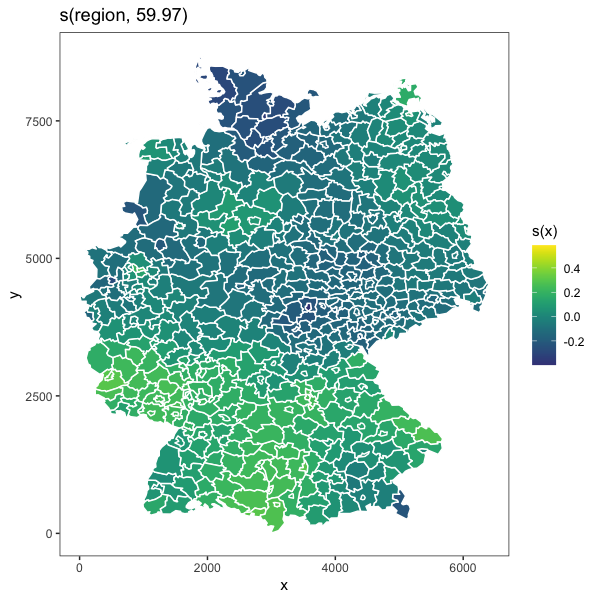

In [28]:
# The mgcViz version, through rpy2
show_r_plot("print(plot(lar3_viz, select = 1))", width=6, height=6)

## fitISO: an isotropic smooth of longitude and latitude

Instead of an MRF, we can model space with a 2D smooth of the district centres,
`s(lo, la)`. It's *isotropic*: one unit east–west and one unit north–south count the
same. Unlike the MRF, this model can be fitted with pymgcv.

R:

```r
fitISO <- gamV(Y ~ s(lo, la, k = 200) + 
                   s(x, k = 20) +
                   offset(log(E)),
               family = poisson,
               data = Larynx)
plot(fitISO, select = 1)
```

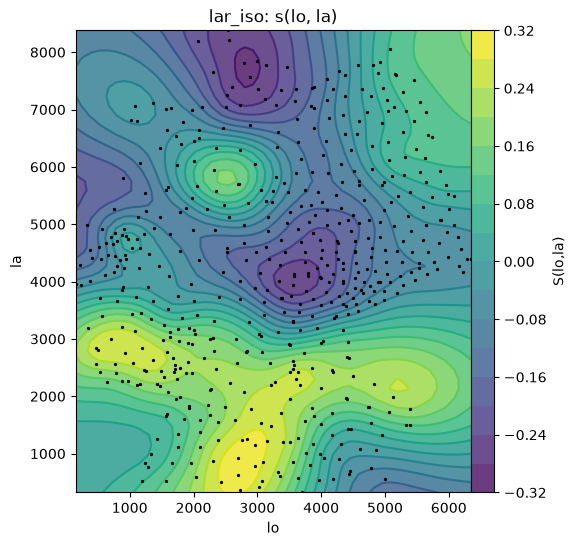

In [29]:
lar_iso = GAM({"Y": [S("lo", "la", k=200),
                     S("x", k=20), 
                     Offset("logE")]},
              family=Poisson())
lar_iso.fit(larynx)

space_term = S("lo", "la", k=200) # We will use the space_term variable in the plot below, instead of repeating S("lo", "la", k=200)

fig, ax = plt.subplots(figsize=(6, 6))
gplt.continuous_2d(term=space_term, gam=lar_iso, ax=ax)
ax.set_title("lar_iso: s(lo, la)");

### 3D view

R uses `plotRGL(sm(fitISO, 1), residuals = TRUE)` for an interactive 3D plot. Here is the
same idea with [plotly](https://plotly.com/python/):

- the **coloured surface** is the estimated effect `s(lo, la)`;
- the two **grey surfaces** above and below are `s(lo, la)` ± 1 standard error, a
  confidence band for the effect (`plotRGL` uses `se.mult = 1` by default). Where they are
  far apart, at the edges and where there are few districts, the estimate is uncertain;
- the **dots** are the partial residuals.

How to use the plot:

- **Drag** with the mouse to rotate the plot.
- **Scroll** to zoom in and out.
- **Hover** over the surface or a dot to see its values.
- Use the icons at the top right to pan or reset the view, or save the plot as a PNG.

In [30]:
lo_grid, la_grid = np.meshgrid(
    np.linspace(larynx["lo"].min(), larynx["lo"].max(), 60),
    np.linspace(larynx["la"].min(), larynx["la"].max(), 60),
)
# compute_se=True also returns the standard error of s(lo, la) at each grid point
effect = lar_iso.partial_effect(
    space_term, data={"lo": lo_grid.ravel(), "la": la_grid.ravel()}, compute_se=True
)
surface = effect.fit.reshape(lo_grid.shape)
se = effect.se.reshape(lo_grid.shape)
partial_res = lar_iso.partial_residuals(space_term)

SE_MULT = 1  # same default as plotRGL(se.mult = 1); use 2 for an approx. 95% band
band = {"colorscale": [[0, "grey"], [1, "grey"]], "showscale": False, "opacity": 0.3}

fig = go.Figure([
    go.Surface(x=lo_grid, y=la_grid, z=surface, colorscale="Viridis", opacity=0.9,
               colorbar={"title": "s(lo, la)"}, name="s(lo, la)"),
    go.Surface(x=lo_grid, y=la_grid, z=surface + SE_MULT * se, name="+ SE", **band),
    go.Surface(x=lo_grid, y=la_grid, z=surface - SE_MULT * se, name="- SE", **band),
    go.Scatter3d(x=larynx["lo"], y=larynx["la"], z=partial_res, mode="markers",
                 marker={"size": 2, "color": "black"}, name="partial residuals"),
])
fig.update_layout(
    width=700, height=600,
    scene={"xaxis_title": "lo", "yaxis_title": "la", "zaxis_title": "s(lo, la)"},
)
fig.show()

> Note: the surface is shown over the whole rectangle of coordinates, including areas
> outside Germany where there is no data. There the smooth is extrapolating, so ignore
> the corners.

### Static 3D view with matplotlib

The same plot with matplotlib's 3D axes. It doesn't rotate in the notebook, so it is
drawn from two angles. It reuses `surface`, `se` and `partial_res` from the cell above,
and the function `plot_surface_static` from [`plot_helpers.py`](plot_helpers.py) (shared
with Demo 4). The translucent grey surfaces are the ± SE surfaces.
Grid points far from any region are hidden here, so the corners where the smooth
extrapolates are not drawn.

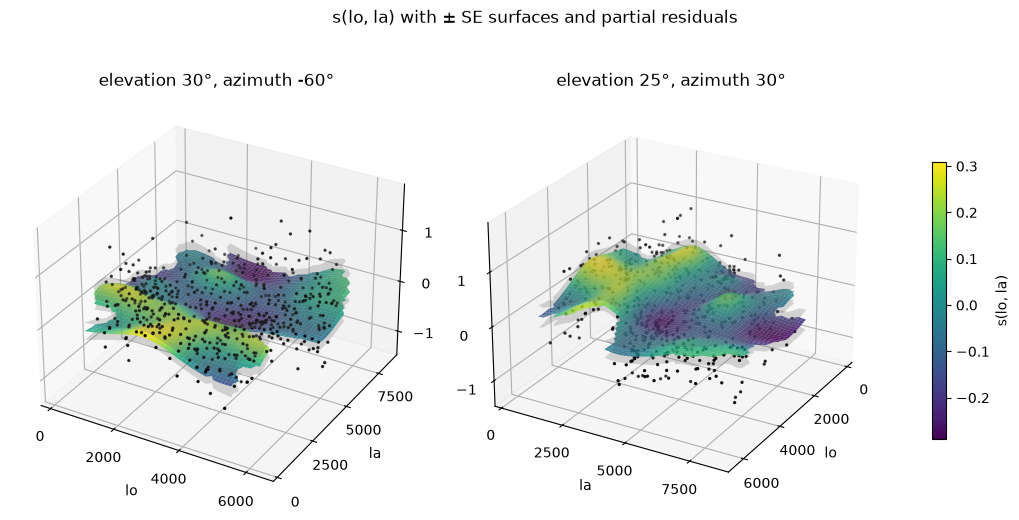

In [31]:
from scipy.spatial import cKDTree

# Hide grid points that are far from every region centre (extrapolation)
dist, _ = cKDTree(larynx[["lo", "la"]].to_numpy()).query(
    np.column_stack([lo_grid.ravel(), la_grid.ravel()])
)
far = (dist > 400).reshape(lo_grid.shape)

plot_surface_static(
    lo_grid, la_grid, surface, se,
    mask=far,
    points=(larynx["lo"], larynx["la"], partial_res),
    se_mult=SE_MULT,
    xlabel="lo", ylabel="la", zlabel="s(lo, la)",
    title="s(lo, la) with ± SE surfaces and partial residuals",
)
